# Entrenamiento de ShuffleNetV2 x1.0 (pesos de ImageNet) — 5 clases de residuos

Este notebook entrena un clasificador de residuos con **ShuffleNetV2 x1.0**, la más ligera de las tres arquitecturas comparadas en el proyecto. Usa el mismo dataset, cabecera, épocas y learning rates que MobileNetV3-Large y EfficientNetB0, para que la comparación sea justa.

**Particularidad importante:** Keras **no** incluye ShuffleNetV2 en `tf.keras.applications`. Por eso:
1.  La arquitectura se **construye a mano**, capa por capa, imitando la versión de `torchvision` (PyTorch).
2.  Los pesos de ImageNet se toman de `torchvision` y se convierten previamente a un archivo `.npz` con `tests/convertir_pesos_shufflenetv2.py`.
3.  El notebook carga ese `.npz` en el modelo de Keras y, a partir de ahí, sigue el mismo proceso de Transfer Learning que los otros modelos.

**Clases que aprende el modelo (5):** `aluminio`, `carton`, `otros`, `plastico`, `vidrio`.

**Archivos que usa y genera:**
* **Entrada:** `models/ShuffleNetV2/pretrained/shufflenet_v2_x1_0_imagenet.npz`
* **Salida:** `models/ShuffleNetV2/modelo_residuos_shufflenetV2_imagenet.keras` y `.tflite`
* **Figura:** `reports/figures/curvas_entrenamiento_ShuffleNetV2_imagenet.png`

**Resultados de la ejecución guardada:** `val_accuracy` de **0.9219** al terminar la fase 1 y de **0.9433** al terminar el fine-tuning. El `.tflite` pesa solo **1.50 MB**.

> 📁 Este notebook vive en `notebooks/ShuffleNetV2/`, por eso las rutas parten de `Path("../..")` (dos niveles arriba = raíz del proyecto) y los modelos se leen/guardan en `models/ShuffleNetV2/`.

### Importación de librerías

Reunimos al inicio todas las herramientas que usará el notebook:

* **`os` y `pathlib.Path`:** manejo de archivos y rutas multiplataforma.
* **`numpy`:** necesario para leer el archivo `.npz` con los pesos de ImageNet.
* **`tensorflow`:** el motor de Deep Learning.
* **`ImageDataGenerator`:** lee las imágenes desde carpetas y les aplica transformaciones en tiempo real.
* **`Dense`, `GlobalAveragePooling2D`, `Dropout`, `Model`:** piezas para construir la cabecera de clasificación.
* **`Adam`:** el optimizador que ajustará los pesos durante el entrenamiento.

A diferencia de los otros notebooks, aquí **no** se importa un modelo de `keras.applications`, porque ShuffleNetV2 no existe ahí: las capas para construirlo se importan más adelante, en la celda de la arquitectura.

In [1]:
import os
from pathlib import Path
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

I0000 00:00:1791931707.315884   59556 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


### Comprobación de GPU

Verifica si TensorFlow ve una **GPU NVIDIA** antes de empezar. Si no la hay, avisa que el entrenamiento correrá en CPU (más lento).

**En la ejecución guardada:** se usó una **NVIDIA GeForce RTX 4050 Laptop**, y cada época tomó unos 3 minutos.

In [2]:
gpus = tf.config.list_physical_devices('GPU')
print(f"¿TensorFlow detecta la GPU?: {len(gpus) > 0}")
if gpus:
    print(f"Detalles del dispositivo: {gpus[0]}")
else:
    print("⚠️ No se detectó GPU. El entrenamiento correrá en CPU (Lento).")

¿TensorFlow detecta la GPU?: True
Detalles del dispositivo: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


### Configuración de rutas y verificación del dataset

Definimos dónde están los datos y dónde se guardará el modelo usando rutas **relativas**, para que el notebook funcione en cualquier computadora sin editar rutas a mano.

**¿Qué hace este código?**
1.  **`BASE_DIR = Path("../..")`:** sube dos niveles desde `notebooks/ShuffleNetV2/` hasta la raíz del proyecto.
2.  **Rutas del dataset:** espera las carpetas `data/raw/waste_classification/train` y `data/raw/waste_classification/test`, cada una con una subcarpeta por clase.
3.  **`MODELS_DIR`:** apunta a `models/ShuffleNetV2/`, la carpeta donde se guardan los modelos de esta arquitectura. Si no existe, la crea.
4.  **Verificación:** si no encuentra `train/` o `test/`, muestra un aviso para que coloques los datos manualmente (este notebook **no** descarga nada de Kaggle).
5.  **`PESOS_IMAGENET`:** ruta al archivo `models/ShuffleNetV2/pretrained/shufflenet_v2_x1_0_imagenet.npz` con los pesos de ImageNet convertidos desde PyTorch.
    * Si el archivo no existe, la celda se detiene con `FileNotFoundError`. Sin esos pesos el modelo partiría de cero y la comparación con los otros modelos (que sí usan ImageNet) no sería justa.
    * Para generarlo, ejecuta una vez `tests/convertir_pesos_shufflenetv2.py` (requiere `torch` y `torchvision`).

*Estructura esperada:*
```
data/raw/waste_classification/
├── train/
│   ├── clase_1/
│   └── ...
└── test/
    ├── clase_1/
    └── ...
```

In [3]:
# Definir rutas relativas a partir del directorio base
BASE_DIR = Path("../..")
DATA_RAW_DIR = BASE_DIR / "data" / "raw"
DATASET_DIR = DATA_RAW_DIR / "waste_classification"
MODELS_DIR = BASE_DIR / "models" / "ShuffleNetV2"

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

# Pesos de ShuffleNetV2 preentrenados en ImageNet.
# Keras NO incluye ShuffleNetV2 en keras.applications, así que no existe un
# weights='imagenet' como en MobileNetV3 o EfficientNetB0. Estos pesos vienen de
# torchvision (shufflenet_v2_x1_0) y se convirtieron al formato de Keras con
# tests/convertir_pesos_shufflenetv2.py
PESOS_IMAGENET = MODELS_DIR / "pretrained" / "shufflenet_v2_x1_0_imagenet.npz"

# Crear carpeta de modelos si no existe
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Verificación estricta de la existencia de los datos
if not TRAIN_DIR.exists() or not TEST_DIR.exists():
    print(f"⚠️ ¡Atención! No se encontró la estructura esperada en {DATASET_DIR}")
    print("Asegúrate de colocar tus carpetas 'train' y 'test' manualmente ahí.")
else:
    print(f"✅ Directorios de datos detectados correctamente en:\n - {TRAIN_DIR}\n - {TEST_DIR}")

# Sin los pesos preentrenados este notebook no tiene sentido: entrenaría desde cero
if not PESOS_IMAGENET.exists():
    raise FileNotFoundError(
        f"No se encontraron los pesos de ImageNet en: {PESOS_IMAGENET}\n"
        "Genéralos con tests/convertir_pesos_shufflenetv2.py (las instrucciones están en ese archivo)."
    )
print(f"✅ Pesos de ImageNet detectados en:\n - {PESOS_IMAGENET}")

✅ Directorios de datos detectados correctamente en:
 - ../data/raw/waste_classification/train
 - ../data/raw/waste_classification/test
✅ Pesos de ImageNet detectados en:
 - ../models/pretrained/shufflenet_v2_x1_0_imagenet.npz


### Carga de imágenes y aumento de datos (Data Augmentation)

En esta celda configuramos cómo "verá" el modelo las imágenes. El dataset ya viene separado en **dos carpetas**: `train/` para aprender y `test/` para validar, así que no hace falta dividirlo con `validation_split`.

**Dos generadores distintos:**
1.  **`train_datagen` (con Data Augmentation):** en cada época aplica cambios aleatorios para que el modelo no memorice las fotos:
    * Rotación de hasta 30° (`rotation_range`).
    * Desplazamiento horizontal y vertical del 20 % (`width_shift_range`, `height_shift_range`).
    * Zoom de hasta 30 % (`zoom_range`).
    * Volteo horizontal tipo espejo (`horizontal_flip`).
    * *Analogía:* es como entrenar a un portero lanzándole balones desde distintos ángulos y con distintos efectos, no siempre al mismo punto.
2.  **`test_datagen` (sin alteraciones):** las imágenes de validación deben llegar tal como son para medir el rendimiento real.

**Preprocesamiento:**
* **Sin `rescale`:** los generadores entregan los píxeles en su rango original (0–255). El modelo que construimos más abajo incluye su propio reescalado (`Rescaling`) y la normalización de ImageNet (`Normalization`) como primeras capas, igual que hacen MobileNetV3 y EfficientNetB0 en Keras.

**Parámetros:**
* **`IMG_SIZE = (224, 224)`:** tamaño de entrada estándar de ShuffleNetV2 y el mismo que MobileNetV3-Large y EfficientNetB0.
* **`BATCH_SIZE = 32`:** cuántas imágenes se procesan a la vez. Los generadores cargan lote por lote, sin meter todo el dataset en la RAM.
* **`shuffle=True`** en entrenamiento (mezclar evita que el modelo aprenda el orden de las carpetas) y **`shuffle=False`** en validación (mantiene el orden para poder comparar predicciones con etiquetas).

**Resultado:** 18 117 imágenes de entrenamiento y 4 534 de validación, repartidas en 5 clases. `NUM_CLASSES` se calcula automáticamente a partir de las carpetas encontradas, así que la última capa del modelo se adapta sola al número de clases.

In [4]:
# Mismo tamaño de imagen y mismo batch que en MobileNetV3-Large y EfficientNetB0,
# para que los tres modelos reciban exactamente los mismos datos.
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# NOTA sobre el preprocesamiento:
# El modelo que construimos más abajo incluye su propio reescalado y su propia
# normalización como primeras capas. Por eso NO se aplica rescale=1./255 aquí:
# el generador entrega píxeles de 0 a 255, igual que en los otros dos modelos.

# 1. Generador de Entrenamiento (CON Data Augmentation)
train_datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.3,
    horizontal_flip=True
)

# 2. Generador de Prueba/Validación (SIN alteraciones)
test_datagen = ImageDataGenerator()

print("Cargando set de ENTRENAMIENTO...")
train_gen = train_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True # Fundamental mezclar para entrenar
)

print("Cargando set de PRUEBA/VALIDACIÓN...")
val_gen = test_datagen.flow_from_directory(
    str(TEST_DIR),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # No se mezcla para poder evaluar ordenadamente
)

NUM_CLASSES = train_gen.num_classes
print(f"\nTotal de clases detectadas: {NUM_CLASSES}")
print(f"Diccionario de clases: {train_gen.class_indices}")

Cargando set de ENTRENAMIENTO...
Found 18117 images belonging to 5 classes.
Cargando set de PRUEBA/VALIDACIÓN...
Found 4534 images belonging to 5 classes.

Total de clases detectadas: 5
Diccionario de clases: {'aluminio': 0, 'carton': 1, 'otros': 2, 'plastico': 3, 'vidrio': 4}


### Construcción de ShuffleNetV2 x1.0 y carga de los pesos de ImageNet

Es la celda más importante del notebook. Como Keras no trae ShuffleNetV2, aquí se **construye la red a mano** y se le cargan los pesos de ImageNet.

#### ¿Qué es ShuffleNetV2?
Arquitectura de Megvii (2018) pensada para dispositivos con muy poca capacidad de cálculo. Sus ideas clave son:
* **Channel split (división de canales):** en cada bloque, la mitad de los canales pasa **sin procesar** y solo la otra mitad atraviesa las convoluciones. Así se ahorra cómputo.
* **Convoluciones depthwise:** filtran cada canal por separado (muy baratas), seguidas de convoluciones 1×1 que mezclan canales.
* **Channel shuffle (barajado de canales):** después de unir las dos mitades, se intercalan los canales para que la información fluya entre ellas en el siguiente bloque.
* *Analogía:* es como dividir un equipo en dos grupos que trabajan en paralelo y, al final de cada ronda, mezclar a los integrantes para que todos compartan lo aprendido.

#### Estructura de la red (x1.0)
`conv1` (24 canales) → `maxpool` → **stage2** (116 canales, 4 bloques) → **stage3** (232 canales, 8 bloques) → **stage4** (464 canales, 4 bloques) → `conv5` (1024 canales). El primer bloque de cada *stage* usa stride 2 (reduce la resolución a la mitad).

#### Funciones auxiliares
* **`batch_norm`, `conv_1x1`, `conv_depthwise`:** atajos para crear capas con la configuración correcta.
* **`channel_shuffle`:** reordena los canales con `reshape` → `transpose` → `reshape`. Se implementa con operaciones nativas de Keras (`keras.ops`) en lugar de capas `Lambda`, para que el modelo guardado se pueda cargar con `load_model()` sin configuraciones especiales.
* **`shufflenet_unit`:** un bloque completo (con stride 1 hace *channel split*; con stride 2 ambas ramas procesan toda la entrada).
* **`build_shufflenet_v2_base`:** ensambla la red completa sin la capa de clasificación (equivalente a `include_top=False`).

#### Detalles para que los pesos de PyTorch encajen
1.  **Nombres de capa** idénticos a los módulos de `torchvision` (p. ej. `stage2_0_branch1_0`), para emparejar cada peso con su capa.
2.  **Relleno explícito** (`ZeroPadding2D(1)`) en las convoluciones con stride 2, como hace PyTorch. El `padding='same'` de Keras rellena de forma asimétrica y desalinearía los filtros aprendidos.
3.  **`epsilon=1e-5`** en `BatchNormalization` (el valor de PyTorch, en lugar del 1e-3 de Keras).
4.  **Normalización de ImageNet** al inicio (`mean = [0.485, 0.456, 0.406]`, `std = [0.229, 0.224, 0.225]`), que es como se entrenó la red original.

#### Carga de pesos (`cargar_pesos_imagenet`)
Recorre las capas del modelo; a cada `Conv2D`/`DepthwiseConv2D` le asigna su `kernel` y a cada `BatchNormalization` sus 4 tensores (`gamma`, `beta`, `moving_mean`, `moving_variance`). Al final **verifica** que no haya quedado ningún tensor sin usar (salvo `fc__*`, la capa de 1000 clases de ImageNet, que se descarta a propósito).

#### Congelamiento
Igual que en los otros modelos, `base_model.trainable = False` para que en la fase 1 solo se entrene la cabecera.

**Resultado de la ejecución guardada:** 280 tensores de ImageNet cargados, **177 capas** y una salida de **7×7×1024** por imagen.

In [5]:
from keras import ops
from tensorflow.keras.layers import (
    Input, Rescaling, Normalization, ZeroPadding2D, Conv2D, DepthwiseConv2D,
    BatchNormalization, ReLU, MaxPool2D, Concatenate,
)
from tensorflow.keras.models import Model

# ARQUITECTURA SHUFFLENETV2 x1.0
# Es la misma red del notebook ShuffleNetV2.ipynb (24 -> 116 -> 232 -> 464 -> 1024 canales),
# pero escrita para que coincida capa por capa con la de torchvision. Eso es lo que
# permite cargarle los pesos de ImageNet. Las diferencias con la versión anterior son:
#   1. Cada capa lleva el nombre del módulo equivalente en torchvision (p. ej. 'stage2_0_branch1_0').
#   2. Las convoluciones con stride 2 usan un relleno explícito de 1 píxel por lado, como PyTorch.
#      El padding='same' de Keras rellena solo abajo/derecha y desalinearía los filtros aprendidos.
#   3. BatchNormalization usa epsilon=1e-5 (el de PyTorch) en lugar del 1e-3 de Keras.
#   4. La entrada se normaliza con la media y desviación de ImageNet, que es como se entrenó la red.

# Media y desviación estándar por canal (RGB) con las que se entrenó en ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def batch_norm(x, nombre):
    return BatchNormalization(epsilon=1e-5, momentum=0.9, name=nombre)(x)


def conv_1x1(x, filtros, nombre):
    return Conv2D(filtros, 1, use_bias=False, name=nombre)(x)


def conv_depthwise(x, strides, nombre):
    if strides == 2:
        x = ZeroPadding2D(1, name=f"{nombre}_pad")(x)
        return DepthwiseConv2D(3, strides=2, padding='valid', use_bias=False, name=nombre)(x)
    return DepthwiseConv2D(3, strides=1, padding='same', use_bias=False, name=nombre)(x)


# Operación de "barajar" los canales: intercala los canales de las dos ramas
# para que la información fluya entre ellas en el siguiente bloque.
# Se usan operaciones nativas de Keras (no capas Lambda), así el modelo guardado
# se puede cargar con load_model() sin custom_objects ni safe_mode=False.
def channel_shuffle(x):
    h, w, c = x.shape[1:]
    x = ops.reshape(x, (-1, h, w, 2, c // 2))
    x = ops.transpose(x, (0, 1, 2, 4, 3))
    return ops.reshape(x, (-1, h, w, c))


# Bloque de construcción básico de ShuffleNetV2
def shufflenet_unit(x, out_channels, strides, nombre):
    mitad = out_channels // 2

    if strides == 2:
        # Bloque de reducción: las dos ramas procesan la entrada completa
        b1 = conv_depthwise(x, 2, f"{nombre}_branch1_0")
        b1 = batch_norm(b1, f"{nombre}_branch1_1")
        b1 = conv_1x1(b1, mitad, f"{nombre}_branch1_2")
        b1 = batch_norm(b1, f"{nombre}_branch1_3")
        b1 = ReLU(name=f"{nombre}_branch1_4")(b1)
        b2 = x
    else:
        # División de canales (Channel Split): la primera mitad pasa intacta
        c = x.shape[-1]
        b1 = x[..., : c // 2]
        b2 = x[..., c // 2 :]

    # Procesamiento de la rama 2
    b2 = conv_1x1(b2, mitad, f"{nombre}_branch2_0")
    b2 = batch_norm(b2, f"{nombre}_branch2_1")
    b2 = ReLU(name=f"{nombre}_branch2_2")(b2)
    b2 = conv_depthwise(b2, strides, f"{nombre}_branch2_3")
    b2 = batch_norm(b2, f"{nombre}_branch2_4")
    b2 = conv_1x1(b2, mitad, f"{nombre}_branch2_5")
    b2 = batch_norm(b2, f"{nombre}_branch2_6")
    b2 = ReLU(name=f"{nombre}_branch2_7")(b2)

    # Concatenación y Barajado
    out = Concatenate(name=f"{nombre}_concat")([b1, b2])
    return channel_shuffle(out)


# Ensamblaje del modelo base (sin cabecera de clasificación, equivalente a include_top=False)
def build_shufflenet_v2_base(input_shape=(224, 224, 3)):
    inputs = Input(shape=input_shape)

    # Preprocesamiento integrado: 0-255 -> 0-1 -> normalización de ImageNet
    x = Rescaling(1. / 255, name="escala_0_1")(inputs)
    x = Normalization(
        mean=IMAGENET_MEAN,
        variance=[s ** 2 for s in IMAGENET_STD],
        name="normalizacion_imagenet",
    )(x)

    # Conv1
    x = ZeroPadding2D(1, name="conv1_0_pad")(x)
    x = Conv2D(24, 3, strides=2, padding='valid', use_bias=False, name="conv1_0")(x)
    x = batch_norm(x, "conv1_1")
    x = ReLU(name="conv1_2")(x)
    x = ZeroPadding2D(1, name="maxpool_pad")(x)
    x = MaxPool2D(pool_size=3, strides=2, padding='valid', name="maxpool")(x)

    # Stage 2 (116 canales, 4 bloques), Stage 3 (232 canales, 8 bloques), Stage 4 (464 canales, 4 bloques)
    for etapa, canales, bloques in [("stage2", 116, 4), ("stage3", 232, 8), ("stage4", 464, 4)]:
        x = shufflenet_unit(x, canales, 2, f"{etapa}_0")
        for i in range(1, bloques):
            x = shufflenet_unit(x, canales, 1, f"{etapa}_{i}")

    # Conv5
    x = conv_1x1(x, 1024, "conv5_0")
    x = batch_norm(x, "conv5_1")
    x = ReLU(name="conv5_2")(x)

    return Model(inputs, x, name="shufflenet_v2_x1_0")


# Carga de los pesos de ImageNet capa por capa, emparejando por nombre
def cargar_pesos_imagenet(modelo, ruta_npz):
    pesos = np.load(ruta_npz)
    usados = set()

    for layer in modelo.layers:
        if isinstance(layer, (Conv2D, DepthwiseConv2D)):
            claves = [f"{layer.name}__kernel"]
        elif isinstance(layer, BatchNormalization):
            claves = [f"{layer.name}__{p}" for p in ("gamma", "beta", "moving_mean", "moving_variance")]
        else:
            continue  # ReLU, padding, concatenación, etc. no tienen pesos
        layer.set_weights([pesos[c] for c in claves])
        usados.update(claves)

    # Verificación: todos los tensores del archivo deben haberse usado.
    # (Las claves 'fc__*' son la capa de 1000 clases de ImageNet, que aquí se descarta.)
    sin_usar = {c for c in pesos.files if not c.startswith("fc__")} - usados
    if sin_usar:
        raise ValueError(f"Quedaron {len(sin_usar)} tensores sin cargar, p. ej.: {sorted(sin_usar)[:3]}")
    return len(usados)


print("Construyendo ShuffleNetV2 x1.0 y cargando pesos de ImageNet...")
base_model = build_shufflenet_v2_base(input_shape=IMG_SIZE + (3,))
tensores_cargados = cargar_pesos_imagenet(base_model, PESOS_IMAGENET)

# --- CONGELAMIENTO DE CAPAS ---
# "Congelamos" el modelo base. Esto significa que sus pesos (números internos)
# NO cambiarán durante la primera fase del entrenamiento.
# Esto nos permite usarlo solo como un "extractor de características" ultra avanzado.
base_model.trainable = False

print("✅ Modelo base cargado y congelado correctamente.")
print(f"   Tensores de ImageNet cargados: {tensores_cargados}")
print(f"   Estructura de entrada: {base_model.input_shape}")
print(f"   Estructura de salida: {base_model.output_shape}")
print(f"   Total de capas: {len(base_model.layers)}")

Construyendo ShuffleNetV2 x1.0 y cargando pesos de ImageNet...


I0000 00:00:1791931710.490850   59556 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3569 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


✅ Modelo base cargado y congelado correctamente.
   Tensores de ImageNet cargados: 280
   Estructura de entrada: (None, 224, 224, 3)
   Estructura de salida: (None, 7, 7, 1024)
   Total de capas: 177


### Construcción de la "cabecera" del modelo (el clasificador)

Tomamos el modelo base (ShuffleNetV2) y le añadimos al final nuestra propia estructura de clasificación.

**Analogía:**
* **ShuffleNetV2 (base):** son los **"ojos"**. Ya saben ver líneas, curvas y texturas complejas.
* **Nueva cabecera (head):** es el **"cerebro"** específico de nuestra tarea. Toma lo que ven los ojos y decide: "¿esto es cartón o vidrio?".

**Capas clave:**
1.  **`GlobalAveragePooling2D`:** "aplasta" los mapas de características 3D que salen del modelo base promediando cada canal. Reduce muchísimo la cantidad de datos (y de parámetros) frente a `Flatten`, algo vital para la Raspberry Pi.
2.  **`Dense(128, relu)`:** capa intermedia que aprende a combinar características visuales (ej.: "brillante" + "cilíndrico" = "lata").
3.  **`Dropout(0.3)`:** apaga al azar el 30 % de las neuronas en cada paso del entrenamiento. Obliga al modelo a no depender de una sola "pista" y reduce el *overfitting*.
4.  **`Dense(NUM_CLASSES, softmax)`:** capa final con una neurona por clase (5). **Softmax** convierte las salidas en **probabilidades** que suman 1 (ej.: 80 % plástico, 15 % vidrio, 5 % otros).

`model.summary()` imprime la tabla de capas y parámetros para verificar que todo quedó bien conectado.

**Importante para la comparación:** la cabecera es **idéntica** a la de MobileNetV3-Large y EfficientNetB0, así que cualquier diferencia de accuracy se debe al modelo base.

In [6]:
# Construcción de la nueva cabecera del modelo.
# Es idéntica a la de MobileNetV3-Large y EfficientNetB0: así cualquier diferencia
# de accuracy se debe al modelo base y no a una cabecera más o menos poderosa.
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x) # Capa intermedia para aprender patrones complejos
x = Dropout(0.3)(x) # Apaga el 30% de neuronas al azar para evitar memorización (overfitting)

# Capa de salida
output = Dense(NUM_CLASSES, activation='softmax')(x)

# Ensamblamos el modelo final
model = Model(inputs=base_model.input, outputs=output)

print("Arquitectura del modelo finalizada.")
model.summary() # Muestra un resumen para verificar que todo conecta bien

Arquitectura del modelo finalizada.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ escala_0_1          │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalizacion_imag… │ (None, 224, 224,  │          0 │ escala_0_1[0][0]  │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_0_pad         │ (None, 226, 226,  │          0 │ normalizacion_im… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_0 (Conv2D)    │ (None, 112, 112,  │        648 │ conv1_0_pad[0][0] │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_1             │ (None, 112, 112,  │         96 │ conv1_0[0][0]     │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_2 (ReLU)      │ (None, 112, 112,  │          0 │ conv1_1[0][0]     │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ maxpool_pad         │ (None, 114, 114,  │          0 │ conv1_2[0][0]     │
│ (ZeroPadding2D)     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ maxpool             │ (None, 56, 56,    │          0 │ maxpool_pad[0][0] │
│ (MaxPooling2D)      │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_0_branch2_0  │ (None, 56, 56,    │      1,392 │ maxpool[0][0]     │
│ (Conv2D)            │ 58)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_0_branch2_1  │ (None, 56, 56,    │        232 │ stage2_0_branch2… │
│ (BatchNormalizatio… │ 58)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_0_branch2_2  │ (None, 56, 56,    │          0 │ stage2_0_branch2… │
│ (ReLU)              │ 58)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_0_branch1_0… │ (None, 58, 58,    │          0 │ maxpool[0][0]     │
│ (ZeroPadding2D)     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_0_branch2_3… │ (None, 58, 58,    │          0 │ stage2_0_branch2… │
│ (ZeroPadding2D)     │ 58)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_0_branch1_0  │ (None, 28, 28,    │        216 │ stage2_0_branch1… │
│ (DepthwiseConv2D)   │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_0_branch2_3  │ (None, 28, 28,    │        522 │ stage2_0_branch2… │
│ (DepthwiseConv2D)   │ 58)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_0_branch1_1  │ (None, 28, 28,    │         96 │ stage2_0_branch1

 Total params: 1,401,629 (5.35 MB)

 Trainable params: 131,845 (515.02 KB)

 Non-trainable params: 1,269,784 (4.84 MB)

### Compilación y entrenamiento — Fase 1 (solo la cabecera)

En esta celda ocurren dos cosas:

1.  **Compilación (`model.compile`):** configuramos las "reglas" con las que el modelo aprenderá.
    * **Optimizador (Adam):** es el "profesor" que corrige al modelo. Cada vez que se equivoca, Adam ajusta los pesos para que la próxima vez lo haga mejor.
    * **Learning rate (`1e-3`):** la velocidad de aprendizaje. *0.001* es un valor estándar y seguro: si es muy alto el modelo no converge; si es muy bajo tarda una eternidad.
    * **Loss (`categorical_crossentropy`):** la "puntuación de error" que el modelo intenta bajar. Se usa la versión *categorical* porque hay más de dos clases y las etiquetas vienen en formato *one-hot*.
    * **Metrics (`accuracy`):** porcentaje de aciertos.

2.  **Entrenamiento (`model.fit`):**
    * **`epochs=15`:** el modelo recorre el dataset de entrenamiento completo 15 veces.
    * **`validation_data=val_gen`:** al final de cada época se evalúa con imágenes que nunca usa para aprender, para saber si realmente generaliza o solo memoriza.
    * Como el modelo base está **congelado**, en esta fase solo se ajustan los pesos de la cabecera nueva.

**Cómo leer la salida:** `accuracy`/`loss` son del set de entrenamiento y `val_accuracy`/`val_loss` del de validación. Si `accuracy` sube mucho más que `val_accuracy`, es señal de *overfitting*.

**Resultado de la ejecución guardada:** tras 15 épocas, `accuracy` = 0.9186 y **`val_accuracy` = 0.9219** (`val_loss` = 0.2326).

In [7]:
# COMPILACIÓN DEL MODELO
# Definimos cómo va a aprender la red neuronal
print("Compilando el modelo con optimizador Adam...")

model.compile(
    optimizer=Adam(learning_rate=1e-3), # 0.001: Velocidad de aprendizaje inicial estándar
    loss='categorical_crossentropy',    # Obligatorio para clasificación de múltiples clases (>2)
    metrics=['accuracy']                # Queremos monitorear qué tan preciso es (0.0 a 1.0)
)

# ENTRENAMIENTO — FASE 1
# Solo se entrena la cabecera que agregamos. El modelo base (ShuffleNetV2) permanece
# congelado y actúa como extractor de características.
# Mismas 15 épocas y mismo learning rate que en MobileNetV3-Large y EfficientNetB0.
print("\nIniciando entrenamiento (Fase 1 - Cabecera)...")
print("   Nota: Esto puede tardar dependiendo de tu hardware (CPU vs GPU).")

history = model.fit(
    train_gen,               # Datos de entrenamiento (con data augmentation)
    validation_data=val_gen, # Datos de validación (para examen final de cada época)
    epochs=15,               # Número de vueltas completas al dataset
    verbose=1                # Muestra una barra de progreso animada
)

print("¡Entrenamiento fase 1 completado!")

Compilando el modelo con optimizador Adam...

Iniciando entrenamiento (Fase 1 - Cabecera)...
   Nota: Esto puede tardar dependiendo de tu hardware (CPU vs GPU).
Epoch 1/15


I0000 00:00:1791931712.548589   59556 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1791931716.161658   59697 service.cc:153] XLA service 0x7faa08065230 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791931716.161673   59697 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791931716.254539   59697 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791931717.018367   59697 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791931717.080234   59697 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_9734__.139


  1/567 ━━━━━━━━━━━━━━━━━━━━ 1:52:50 12s/step - accuracy: 0.2812 - loss: 1.6042

I0000 00:00:1791931724.477722   59697 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


248/567 ━━━━━━━━━━━━━━━━━━━━ 1:42 323ms/step - accuracy: 0.5377 - loss: 1.2290

/home/eduarduar/dev/EntrenamientoIA/venv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


365/567 ━━━━━━━━━━━━━━━━━━━━ 1:05 324ms/step - accuracy: 0.5842 - loss: 1.1288

I0000 00:00:1791931843.142709   59696 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_9734__.139


567/567 ━━━━━━━━━━━━━━━━━━━━ 231s 388ms/step - accuracy: 0.7389 - loss: 0.7527 - val_accuracy: 0.8602 - val_loss: 0.4466
Epoch 2/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 191s 338ms/step - accuracy: 0.8411 - loss: 0.4640 - val_accuracy: 0.8785 - val_loss: 0.3689
Epoch 3/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 179s 316ms/step - accuracy: 0.8627 - loss: 0.3980 - val_accuracy: 0.8858 - val_loss: 0.3333
Epoch 4/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 186s 327ms/step - accuracy: 0.8733 - loss: 0.3608 - val_accuracy: 0.8886 - val_loss: 0.3253
Epoch 5/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 178s 314ms/step - accuracy: 0.8802 - loss: 0.3433 - val_accuracy: 0.8937 - val_loss: 0.3110
Epoch 6/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 178s 313ms/step - accuracy: 0.8892 - loss: 0.3249 - val_accuracy: 0.9021 - val_loss: 0.2855
Epoch 7/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 172s 304ms/step - accuracy: 0.8893 - loss: 0.3105 - val_accuracy: 0.9014 - val_loss: 0.2805
Epoch 8/15
567/567 ━━━━━━━━━━━━━━━━━━━━ 182s 322ms/step - accuracy: 0.8973 - loss: 0.29

### Fine-tuning (Fase 2: afinamiento de precisión)

Hasta ahora solo entrenamos la "cabecera". El "cuerpo" (ShuffleNetV2) seguía congelado con lo que aprendió en ImageNet. Ahora desbloqueamos una parte para que se adapte mejor a *nuestras* imágenes de residuos.

**Estrategia "70/30":**
1.  **Descongelar parcialmente:** se permite que el **30 % superior** de las capas del modelo base aprenda.
    * *¿Por qué?* Las primeras capas detectan bordes y texturas simples (útiles para cualquier imagen). Las últimas detectan formas complejas, y esas sí conviene adaptarlas para reconocer botellas aplastadas o cartón arrugado.
2.  **Congelar el 70 % inferior:** se mantiene intacto para no perder estabilidad.
    * En este modelo: **177 capas** en total → **123 congeladas** y **54 entrenables**.

**⚠️ Cambio crítico: learning rate**
* Bajamos de `1e-3` a **`1e-5`** (100 veces más pequeño).
* **Razón:** el modelo ya sabe bastante, ahora solo queremos **ajustes microscópicos**. Con una tasa alta se destruiría el conocimiento previo (*catastrophic forgetting*).
* Es **obligatorio volver a compilar** después de cambiar qué capas son entrenables; si no, Keras ignora el cambio.

**Entrenamiento:** 20 épocas más sobre los mismos generadores. El objeto `history_fine` guarda la evolución de esta fase.

**Resultado de la ejecución guardada:** tras 20 épocas, `accuracy` = 0.9439 y **`val_accuracy` = 0.9433** (`val_loss` = 0.1784).

> ℹ️ El 70/30 se calcula sobre la lista de capas de Keras, que incluye capas sin pesos (ReLU, padding, concatenaciones). Por eso las 54 capas "entrenables" no equivalen exactamente al 30 % de los parámetros.

In [8]:
print("Iniciando configuración de Fine-Tuning...")

# Descongelamos todo el modelo base primero
base_model.trainable = True

# Decidimos dónde cortar: Congelaremos el 70% inferior.
# Misma proporción que en MobileNetV3-Large y EfficientNetB0.
fine_tune_at = int(len(base_model.layers) * 0.7)

# Congelamos las capas anteriores al punto de corte
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"   Total de capas en ShuffleNetV2: {len(base_model.layers)}")
print(f"   Capas congeladas (70%): {fine_tune_at}")
print(f"   Capas entrenables (30%): {len(base_model.layers) - fine_tune_at}")

# RE-COMPILACIÓN (Obligatorio después de descongelar)
# ¡IMPORTANTE! Usamos un Learning Rate MUY BAJO (1e-5)
# Esto es para hacer "micro-ajustes" sin romper los pesos ya aprendidos.
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\nIniciando Fase 2 de Entrenamiento (Fine-Tuning)...")
print("   Nota: Esto tomará más tiempo por época, pero mejorará la precisión.")

# Entrenamiento final
history_fine = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20 # Entrenamos por 20 épocas más
)

print("¡Entrenamiento completo finalizado!")

Iniciando configuración de Fine-Tuning...
   Total de capas en ShuffleNetV2: 177
   Capas congeladas (70%): 123
   Capas entrenables (30%): 54

Iniciando Fase 2 de Entrenamiento (Fine-Tuning)...
   Nota: Esto tomará más tiempo por época, pero mejorará la precisión.
Epoch 1/20


I0000 00:00:1791934470.817302   59697 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_71288__.211


 74/567 ━━━━━━━━━━━━━━━━━━━━ 2:17 279ms/step - accuracy: 0.7405 - loss: 0.6955

I0000 00:00:1791934500.766213   59696 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_71288__.211


567/567 ━━━━━━━━━━━━━━━━━━━━ 214s 347ms/step - accuracy: 0.8548 - loss: 0.4043 - val_accuracy: 0.9030 - val_loss: 0.2779
Epoch 2/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 187s 331ms/step - accuracy: 0.8843 - loss: 0.3217 - val_accuracy: 0.9096 - val_loss: 0.2580
Epoch 3/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 178s 315ms/step - accuracy: 0.8954 - loss: 0.2968 - val_accuracy: 0.9144 - val_loss: 0.2410
Epoch 4/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 179s 316ms/step - accuracy: 0.9026 - loss: 0.2728 - val_accuracy: 0.9197 - val_loss: 0.2402
Epoch 5/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 188s 332ms/step - accuracy: 0.9080 - loss: 0.2608 - val_accuracy: 0.9195 - val_loss: 0.2326
Epoch 6/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 192s 339ms/step - accuracy: 0.9123 - loss: 0.2483 - val_accuracy: 0.9235 - val_loss: 0.2246
Epoch 7/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 182s 321ms/step - accuracy: 0.9157 - loss: 0.2376 - val_accuracy: 0.9232 - val_loss: 0.2241
Epoch 8/20
567/567 ━━━━━━━━━━━━━━━━━━━━ 181s 319ms/step - accuracy: 0.9183 - loss: 0.23

### Guardado del modelo (la "copia maestra")

Una vez terminado el entrenamiento guardamos todo lo que aprendió el modelo en un solo archivo.

**Detalles técnicos:**
1.  **Formato `.keras`:** es el formato nativo de **Keras 3**. Es un archivo comprimido (zip) que contiene:
    * La arquitectura (las capas que diseñamos).
    * Los pesos (lo que aprendió).
    * La configuración del optimizador (para poder reanudar el entrenamiento si hiciera falta).
2.  **Ruta de salida:** `models/ShuffleNetV2/modelo_residuos_shufflenetV2_imagenet.keras`. Si la carpeta no existe (por ejemplo, porque no se bajó de git), el código la crea.
3.  Al final imprime la **ruta absoluta**, para no tener dudas de dónde quedó el archivo.

**Nota:** este archivo es el respaldo de alta calidad. Para la Raspberry Pi se usa la versión `.tflite` que se genera en la siguiente celda.

El nombre termina en `_imagenet` para distinguirlo de una versión anterior entrenada desde cero (`modelo_residuos_shufflenetV2_nativo`), que ya no forma parte del repositorio.

In [9]:
# GUARDADO DEL MODELO

# Aseguramos que el directorio de modelos exista
# Si un compañero borró la carpeta 'models' o no se bajó de git, esto la crea.
if not MODELS_DIR.exists():
    print(f"La carpeta {MODELS_DIR} no existía. Creándola...")
    MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Se guarda con un nombre distinto al del modelo entrenado desde cero
# (modelo_residuos_shufflenetV2_nativo.keras) para conservar ambos y poder compararlos.
model_save_path = MODELS_DIR / "modelo_residuos_shufflenetV2_imagenet.keras"

print(f"Guardando modelo maestro en: {model_save_path} ...")
model.save(model_save_path)

# Confirmación visual con ruta absoluta para evitar confusiones sobre dónde se guardó el modelo
print(f"¡Éxito! El archivo está listo.")
print(f"   Ruta absoluta: {model_save_path.resolve()}")

Guardando modelo maestro en: ../models/modelo_residuos_shufflenetV2_imagenet.keras ...
¡Éxito! El archivo está listo.
   Ruta absoluta: /home/eduarduar/dev/EntrenamientoIA/models/modelo_residuos_shufflenetV2_imagenet.keras


### Conversión a TensorFlow Lite (IoT y Edge AI)

Este paso es necesario para ejecutar el modelo en la Raspberry Pi de forma fluida: convertimos el modelo `.keras` al formato `.tflite`.

**¿Qué hace la conversión?**
1.  **Traducción:** `TFLiteConverter.from_keras_model` reescribe el modelo como un grafo de operaciones simplificado que el intérprete de TensorFlow Lite ejecuta eficientemente en procesadores ARM.
2.  **Cuantización (`tf.lite.Optimize.DEFAULT`):**
    * Aplica *dynamic range quantization*: los **pesos** se guardan como enteros de **8 bits** en lugar de flotantes de 32 bits.
    * *Resultado:* el archivo pesa aproximadamente 4 veces menos y la inferencia en CPU suele ser más rápida.
    * *Impacto:* la precisión normalmente cambia muy poco, pero conviene verificarla evaluando el `.tflite` (ver `tests/Evaluate_tflite.py` / `tests/comparar_modelos_inferencia.py`).
3.  **Guardado:** escribe el archivo en `models/ShuffleNetV2/modelo_residuos_shufflenetV2_imagenet.tflite`.
4.  **Reporte de optimización:** compara el tamaño del `.keras` contra el `.tflite`.

**Resultado de la ejecución guardada:** 14.63 MB (`.keras`) → **1.50 MB** (`.tflite`), es decir, **89.74 % menos**.

> ℹ️ El `.keras` pesa más que solo los pesos del modelo porque también incluye el estado del optimizador Adam; por eso la reducción es mayor al 75 % esperado solo por la cuantización.

Es el `.tflite` más ligero de los tres modelos comparados (MobileNetV3-Large: 3.24 MB, EfficientNetB0: 4.50 MB).

In [10]:
print("Iniciando conversión a TFLite...")

# Cargar el convertidor desde el modelo Keras en memoria
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Aplicar optimizaciones — Cuantización
# Esto reduce el tamaño del archivo y acelera la inferencia en la Raspberry Pi
# sin sacrificar casi nada de precisión.
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Realizar la conversión
tflite_model = converter.convert()

# Guardar el archivo .tflite
tflite_save_path = MODELS_DIR / "modelo_residuos_shufflenetV2_imagenet.tflite"

with open(tflite_save_path, "wb") as f:
    f.write(tflite_model)

print(f"Modelo TFLite guardado en: {tflite_save_path}")

# --- COMPARACIÓN DE TAMAÑOS ---
# Esto es meramente para mostrar en el reporte final
keras_size = os.path.getsize(model_save_path) / (1024 * 1024)
tflite_size = os.path.getsize(tflite_save_path) / (1024 * 1024)

print(f"\nReporte de Optimización:")
print(f"   Tamaño Original (.keras): {keras_size:.2f} MB")
print(f"   Tamaño Optimizado (.tflite): {tflite_size:.2f} MB")
print(f"   Reducción de tamaño: {((keras_size - tflite_size) / keras_size) * 100:.2f}% menos")

Iniciando conversión a TFLite...
INFO:tensorflow:Assets written to: /tmp/tmpmt40mx94/assets


INFO:tensorflow:Assets written to: /tmp/tmpmt40mx94/assets


Saved artifact at '/tmp/tmpmt40mx94'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  140362689770704: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  140362302017360: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  140362689263760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140362302017552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140362302017744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140362302018896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140362302016592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140362302024272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140362302024464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140362302023120: TensorSpec(shape=(), dtype=tf.resource, name=None

W0000 00:00:1791938064.057408   59556 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791938064.057427   59556 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1791938064.058179   59556 reader.cc:83] Reading SavedModel from: /tmp/tmpmt40mx94
I0000 00:00:1791938064.065174   59556 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1791938064.065188   59556 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpmt40mx94
I0000 00:00:1791938064.128870   59556 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1791938064.139996   59556 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1791938064.540070   59556 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpmt40mx94
I0000 00:00:1791938064.642110   59556 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 583942 microseconds.


### Curvas de entrenamiento (accuracy y loss)

Para documentar el entrenamiento unimos el historial de las **dos fases** (`history` + `history_fine`) y lo graficamos en una sola figura.

**¿Qué muestra la gráfica?**
* **Izquierda — Accuracy:** aciertos en entrenamiento (`Train`) y en validación (`Val`) época por época.
* **Derecha — Loss:** el error en entrenamiento y en validación.
* **Línea roja punteada:** marca la época 15, donde termina la fase 1 y empieza el *fine-tuning*.

**Cómo interpretarla:**
* Si ambas curvas de accuracy suben juntas y las de loss bajan juntas, el modelo está generalizando bien.
* Si `Train Accuracy` sigue subiendo mientras `Val Accuracy` se estanca o baja, hay *overfitting*.
* Es normal ver un pequeño salto justo después de la línea roja: al descongelar capas el modelo vuelve a ajustarse.

La figura se guarda en `reports/figures/curvas_entrenamiento_ShuffleNetV2_imagenet.png` para usarla en el reporte comparativo de ShuffleNetV2 (ImageNet).

> ℹ️ Aquí el inicio del fine-tuning se calcula automáticamente con `len(history.history['accuracy'])`, así que se ajusta solo si cambias las épocas de la fase 1.

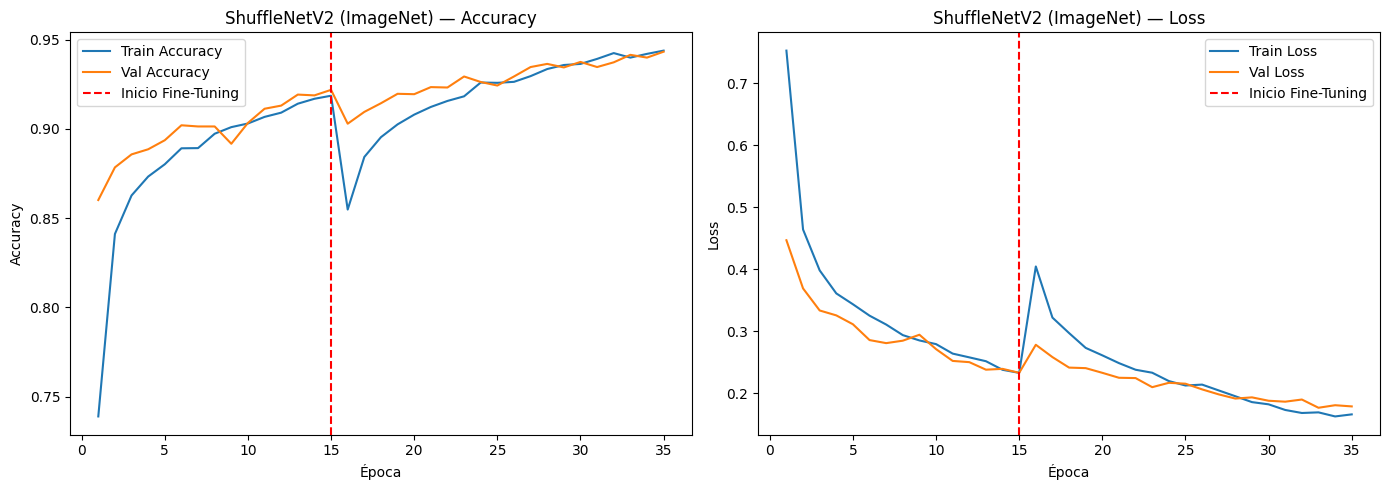

Gráfica guardada.


In [11]:
import matplotlib.pyplot as plt

# Unir el historial de ambas fases para graficar la evolución completa del entrenamiento.
# La línea vertical roja marca el cambio de la fase de cabecera al fine-tuning.
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']

epochs_total = range(1, len(acc) + 1)
fine_tune_start = len(history.history['accuracy'])  # Época donde empieza el fine-tuning

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_total, acc, label='Train Accuracy')
ax1.plot(epochs_total, val_acc, label='Val Accuracy')
ax1.axvline(x=fine_tune_start, color='r', linestyle='--', label='Inicio Fine-Tuning')
ax1.set_title('ShuffleNetV2 (ImageNet) — Accuracy')
ax1.set_xlabel('Época')
ax1.set_ylabel('Accuracy')
ax1.legend()

ax2.plot(epochs_total, loss, label='Train Loss')
ax2.plot(epochs_total, val_loss, label='Val Loss')
ax2.axvline(x=fine_tune_start, color='r', linestyle='--', label='Inicio Fine-Tuning')
ax2.set_title('ShuffleNetV2 (ImageNet) — Loss')
ax2.set_xlabel('Época')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()

FIGURES_DIR = BASE_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / "curvas_entrenamiento_ShuffleNetV2_imagenet.png", dpi=150)
plt.show()
print("Gráfica guardada.")